# 5. Comparación estadística de los modelos

Secciones 5.1–5.4 del enunciado:

1. **Prueba de DeLong** (obligatoria) con la versión rápida O(n log n) de Sun y Xu (2014),
   validada primero frente a la versión directa O(n²).
2. Dos familias de comparaciones de AUC: entre entornos (6) y entre modelos dentro de cada
   entorno (15 + 15), con corrección de **Holm** (α = 0.05) dentro de cada familia.
3. Pruebas complementarias de **McNemar** y **bootstrap pareado** (B = 2000) sobre las 6
   comparaciones entre entornos y el par de modelos con mayor AUC de cada entorno.

**Margen de relevancia práctica (definido de antemano):** |ΔAUC| ≥ 0.005. Con ~269 mil
observaciones de prueba el error estándar de una diferencia de AUC entre modelos
correlacionados es del orden de 0.001, así que diferencias minúsculas resultan
"significativas". Un ΔAUC de 0.005 equivale a 1 punto del coeficiente de Gini
(Gini = 2·AUC − 1), la unidad con la que suele reportarse el poder discriminante de un
modelo de riesgo de crédito; diferencias menores no alteran de forma apreciable la
ordenación de la cartera, por eso se adopta como umbral de relevancia.

In [1]:
import sys  # Permite modificar la ruta de búsqueda de módulos
sys.path.insert(0, "..")  # Agrega la raíz del proyecto
import itertools  # Generación de pares de modelos
import time  # Medición de tiempos
import numpy as np  # Cálculo numérico
import pandas as pd  # Manipulación de datos
import matplotlib.pyplot as plt  # Gráficos
import seaborn as sns  # Mapas de calor
from sklearn.metrics import roc_auc_score  # AUC de referencia para verificar
from src import config as cfg  # Configuración central
from src import delong  # Implementación de la prueba de DeLong
from src.pruebas import bootstrap_pareado, holm, prueba_mcnemar  # Pruebas complementarias
from src.utilidades import guardar_figura, leer_json  # Utilidades

pd.set_option("display.float_format", lambda x: f"{x:.6g}")  # Formato numérico compacto
pd.set_option("display.max_columns", 40)  # Muestra hasta 40 columnas
pd.set_option("display.width", 250)  # Ancho de impresión

## 5.1 Validación de la implementación rápida de DeLong

(a) Datos sintéticos con empates; (b) un subconjunto pequeño de las puntuaciones reales.

In [2]:
val = delong.validar_rapido_vs_directo(n=800, k=4, semilla=7)  # Compara ambas versiones en datos sintéticos
print("Máx. |ΔAUC| rápido vs directo:", val["max_dif_auc"])  # Diferencia de AUC
print("Máx. |Δcov| rápido vs directo:", val["max_dif_cov"])  # Diferencia de covarianza
assert val["max_dif_auc"] < 1e-10 and val["max_dif_cov"] < 1e-10  # Detiene el notebook si no coinciden

Máx. |ΔAUC| rápido vs directo: 1.1102230246251565e-16
Máx. |Δcov| rápido vs directo: 1.0842021724855044e-19


In [3]:
def cargar(entorno):  # Carga las puntuaciones de test de los seis modelos de un entorno
    carpeta = cfg.DIR_SCORES_SK if entorno == "sklearn" else cfg.DIR_SCORES_SP  # Carpeta del entorno
    tablas = []  # Lista de DataFrames
    for nombre in cfg.NOMBRES_MODELOS:  # Recorre los modelos
        s = pd.read_parquet(carpeta / f"{nombre}.parquet").set_index(cfg.COL_ID)  # Lee id, default, score
        tablas.append(s["score"].rename(f"{entorno}|{nombre}"))  # Renombra la puntuación
        etiqueta = s[cfg.COL_TARGET].rename(f"y_{entorno}")  # Etiqueta real de ese entorno
    return pd.concat(tablas + [etiqueta], axis=1)  # Une todo por id

sk = cargar("sklearn")  # Puntuaciones de scikit-learn
sp = cargar("pyspark")  # Puntuaciones de PySpark
datos = sk.join(sp, how="inner").sort_index()  # Une ambos entornos por id (mismas observaciones)
assert len(datos) == len(sk) == len(sp)  # Verifica que ambos entornos evaluaron exactamente las mismas filas
assert (datos["y_sklearn"] == datos["y_pyspark"]).all()  # Verifica que las etiquetas coinciden
y = datos["y_sklearn"].to_numpy()  # Vector común de etiquetas reales
print(f"Observaciones de test comunes: {len(datos):,}  (positivos: {y.sum():,}, {100 * y.mean():.2f} %)")  # Tamaño del test

Observaciones de test comunes: 269,062  (positivos: 53,712, 19.96 %)


In [4]:
idx = np.random.default_rng(0).choice(len(y), 3000, replace=False)  # 3.000 observaciones reales para validar
cols = ["sklearn|LogisticRegression", "sklearn|GradientBoosting", "pyspark|GradientBoosting"]  # Tres modelos reales
auc_d, cov_d = delong.delong_directo(y[idx], datos[cols].to_numpy()[idx].T)  # Versión directa O(n²)
mat, m = delong._ordenar_por_clase(y[idx], datos[cols].to_numpy()[idx].T)  # Entrada ordenada para la rápida
auc_r, cov_r = delong.delong_rapido(mat, m)  # Versión rápida O(n log n)
print("AUC directo:", auc_d, "\nAUC rápido: ", auc_r)  # AUC de ambas versiones
print("Máx. |Δcov|:", np.abs(cov_d - cov_r).max())  # Diferencia de covarianzas
assert np.allclose(auc_d, auc_r) and np.allclose(cov_d, cov_r)  # Coinciden también en datos reales

AUC directo: [0.69955206 0.70221052 0.70565417] 
AUC rápido:  [0.69955206 0.70221052 0.70565417]
Máx. |Δcov|: 2.710505431213761e-20


## AUC de cada modelo con IC 95 % (DeLong)

In [5]:
filas = []  # Lista de resultados
for col in [c for c in datos.columns if "|" in c]:  # Recorre las 12 puntuaciones
    auc, li, ls = delong.ic_auc(y, datos[col].to_numpy())  # AUC e intervalo de DeLong
    entorno, modelo = col.split("|")  # Separa entorno y modelo
    filas.append({"entorno": entorno, "modelo": modelo, "AUC": auc, "IC95_inf": li, "IC95_sup": ls,  # Guarda el resultado
                  "AUC_sklearn_metrics": roc_auc_score(y, datos[col])})  # Verificación con scikit-learn
tabla_auc = pd.DataFrame(filas).pivot(index="modelo", columns="entorno", values=["AUC", "IC95_inf", "IC95_sup"]).reindex(cfg.NOMBRES_MODELOS)  # Tabla modelo × entorno
tabla_auc  # Muestra la tabla

AUC          IC95_inf          IC95_sup         
entorno             pyspark  sklearn  pyspark  sklearn  pyspark  sklearn
modelo                                                                  
LogisticRegression 0.714113 0.714102 0.711751 0.711741 0.716474 0.716463
DecisionTree       0.701812 0.704262 0.699409 0.701869 0.704214 0.706656
RandomForest       0.714218 0.715276 0.711855 0.712916 0.716582 0.717635
GradientBoosting   0.720775  0.72073 0.718436  0.71839 0.723114 0.723069
LinearSVC           0.67932 0.529334 0.676908 0.526585 0.681733 0.532084
NaiveBayes         0.679458 0.679154 0.676984 0.676681 0.681932 0.681626

## Familia 1: mismo modelo, scikit-learn vs. PySpark (6 comparaciones)

In [6]:
filas = []  # Resultados de la familia 1
for modelo in cfg.NOMBRES_MODELOS:  # Recorre los modelos
    r = delong.prueba_delong(y, datos[f"sklearn|{modelo}"].to_numpy(), datos[f"pyspark|{modelo}"].to_numpy())  # DeLong sklearn vs PySpark
    filas.append({"comparacion": f"{modelo}: sklearn vs PySpark", **r})  # Guarda el resultado
fam1 = pd.DataFrame(filas).set_index("comparacion")  # Tabla de la familia
fam1["p_holm"], fam1["significativa"] = holm(fam1["p_valor"], cfg.ALFA)  # Corrección de Holm
fam1["relevante"] = fam1["delta_auc"].abs() >= cfg.MARGEN_RELEVANCIA_AUC  # Relevancia práctica
fam1  # Muestra la tabla

,auc_1,ic_1_inf,ic_1_sup,auc_2,ic_2_inf,ic_2_sup,delta_auc,delta_ic_inf,delta_ic_sup,z,p_valor,p_holm,significativa,relevante
comparacion,,,,,,,,,,,,,,
LogisticRegression: sklearn vs PySpark,0.714102,0.711741,0.716463,0.714113,0.711751,0.716474,-1.11431e-05,-3.39499e-05,1.16637e-05,-0.957612,0.338259,0.676517,False,False
DecisionTree: sklearn vs PySpark,0.704262,0.701869,0.706656,0.701812,0.699409,0.704214,0.00245089,0.00149492,0.00340686,5.0249,5.03692e-07,1.51108e-06,True,False
RandomForest: sklearn vs PySpark,0.715276,0.712916,0.717635,0.714218,0.711855,0.716582,0.00105734,0.000731372,0.00138331,6.3575,2.05068e-10,8.20271e-10,True,False
GradientBoosting: sklearn vs PySpark,0.72073,0.71839,0.723069,0.720775,0.718436,0.723114,-4.54533e-05,-0.00043838,0.000347473,-0.226727,0.820636,0.820636,False,False
LinearSVC: sklearn vs PySpark,0.529334,0.526585,0.532084,0.67932,0.676908,0.681733,-0.149986,-0.153423,-0.146549,-85.5268,0,0,True,True
NaiveBayes: sklearn vs PySpark,0.679154,0.676681,0.681626,0.679458,0.676984,0.681932,-0.00030454,-0.000359848,-0.000249232,-10.7921,3.75161e-27,1.87581e-26,True,False


## Familia 2: todos los pares de modelos dentro de cada entorno (15 + 15)

In [7]:
dentro = {}  # Resultados por entorno
for entorno in ["sklearn", "pyspark"]:  # Recorre los dos entornos
    filas = []  # Resultados del entorno
    for a, b in itertools.combinations(cfg.NOMBRES_MODELOS, 2):  # Los 15 pares de modelos
        r = delong.prueba_delong(y, datos[f"{entorno}|{a}"].to_numpy(), datos[f"{entorno}|{b}"].to_numpy())  # DeLong del par
        filas.append({"modelo_1": a, "modelo_2": b, **r})  # Guarda el resultado
    t = pd.DataFrame(filas)  # Tabla del entorno
    t["p_holm"], t["significativa"] = holm(t["p_valor"], cfg.ALFA)  # Holm dentro de la familia del entorno
    t["relevante"] = t["delta_auc"].abs() >= cfg.MARGEN_RELEVANCIA_AUC  # Relevancia práctica
    dentro[entorno] = t  # Guarda la tabla
    print(f"\n=== {entorno} ===")  # Encabezado
    display(t[["modelo_1", "modelo_2", "auc_1", "auc_2", "delta_auc", "delta_ic_inf", "delta_ic_sup", "z", "p_valor", "p_holm", "significativa", "relevante"]])  # Muestra la tabla


=== sklearn ===


,modelo_1,modelo_2,auc_1,auc_2,delta_auc,delta_ic_inf,delta_ic_sup,z,p_valor,p_holm,significativa,relevante
0,LogisticRegression,DecisionTree,0.714102,0.704262,0.00983909,0.00871106,0.0109671,17.0956,1.59938e-65,3.19875e-65,True,True
1,LogisticRegression,RandomForest,0.714102,0.715276,-0.00117403,-0.00190448,-0.000443575,-3.15017,0.00163173,0.00163173,True,False
2,LogisticRegression,GradientBoosting,0.714102,0.72073,-0.0066281,-0.00730878,-0.00594743,-19.0853,3.34269e-81,1.33708e-80,True,True
3,LogisticRegression,LinearSVC,0.714102,0.529334,0.184767,0.181422,0.188113,108.251,0,0,True,True
4,LogisticRegression,NaiveBayes,0.714102,0.679154,0.0349479,0.0333709,0.036525,43.4327,0,0,True,True
5,DecisionTree,RandomForest,0.704262,0.715276,-0.0110131,-0.0119122,-0.0101141,-24.0088,2.24967e-127,1.12484e-126,True,True
6,DecisionTree,GradientBoosting,0.704262,0.72073,-0.0164672,-0.0174378,-0.0154965,-33.2512,1.96082e-242,1.37258e-241,True,True
7,DecisionTree,LinearSVC,0.704262,0.529334,0.174928,0.171606,0.17825,103.215,0,0,True,True
8,DecisionTree,NaiveBayes,0.704262,0.679154,0.0251089,0.0231642,0.0270536,25.3059,2.74968e-141,1.64981e-140,True,True
9,RandomForest,GradientBoosting,0.715276,0.72073,-0.00545408,-0.0060609,-0.00484726,-17.6161,1.85286e-69,5.55858e-69,True,True



=== pyspark ===


,modelo_1,modelo_2,auc_1,auc_2,delta_auc,delta_ic_inf,delta_ic_sup,z,p_valor,p_holm,significativa,relevante
0,LogisticRegression,DecisionTree,0.714113,0.701812,0.0123011,0.011205,0.0133972,21.9962,3.13241e-107,1.5662e-106,True,True
1,LogisticRegression,RandomForest,0.714113,0.714218,-0.000105541,-0.000839908,0.000628825,-0.281681,0.778188,1,False,False
2,LogisticRegression,GradientBoosting,0.714113,0.720775,-0.00666241,-0.00739069,-0.00593413,-17.9301,6.87084e-72,2.06125e-71,True,True
3,LogisticRegression,LinearSVC,0.714113,0.67932,0.0347926,0.033291,0.0362942,45.4138,0,0,True,True
4,LogisticRegression,NaiveBayes,0.714113,0.679458,0.0346545,0.0330926,0.0362165,43.4862,0,0,True,True
5,DecisionTree,RandomForest,0.701812,0.714218,-0.0124067,-0.0132178,-0.0115956,-29.9799,1.79529e-197,1.43623e-196,True,True
6,DecisionTree,GradientBoosting,0.701812,0.720775,-0.0189635,-0.0199725,-0.0179546,-36.8389,4.40073e-297,3.96065e-296,True,True
7,DecisionTree,LinearSVC,0.701812,0.67932,0.0224915,0.0208043,0.0241786,26.1282,1.74267e-150,1.21987e-149,True,True
8,DecisionTree,NaiveBayes,0.701812,0.679458,0.0223534,0.0204476,0.0242593,22.9878,6.17191e-117,3.70314e-116,True,True
9,RandomForest,GradientBoosting,0.714218,0.720775,-0.00655687,-0.00724261,-0.00587114,-18.7409,2.29811e-78,9.19245e-78,True,True


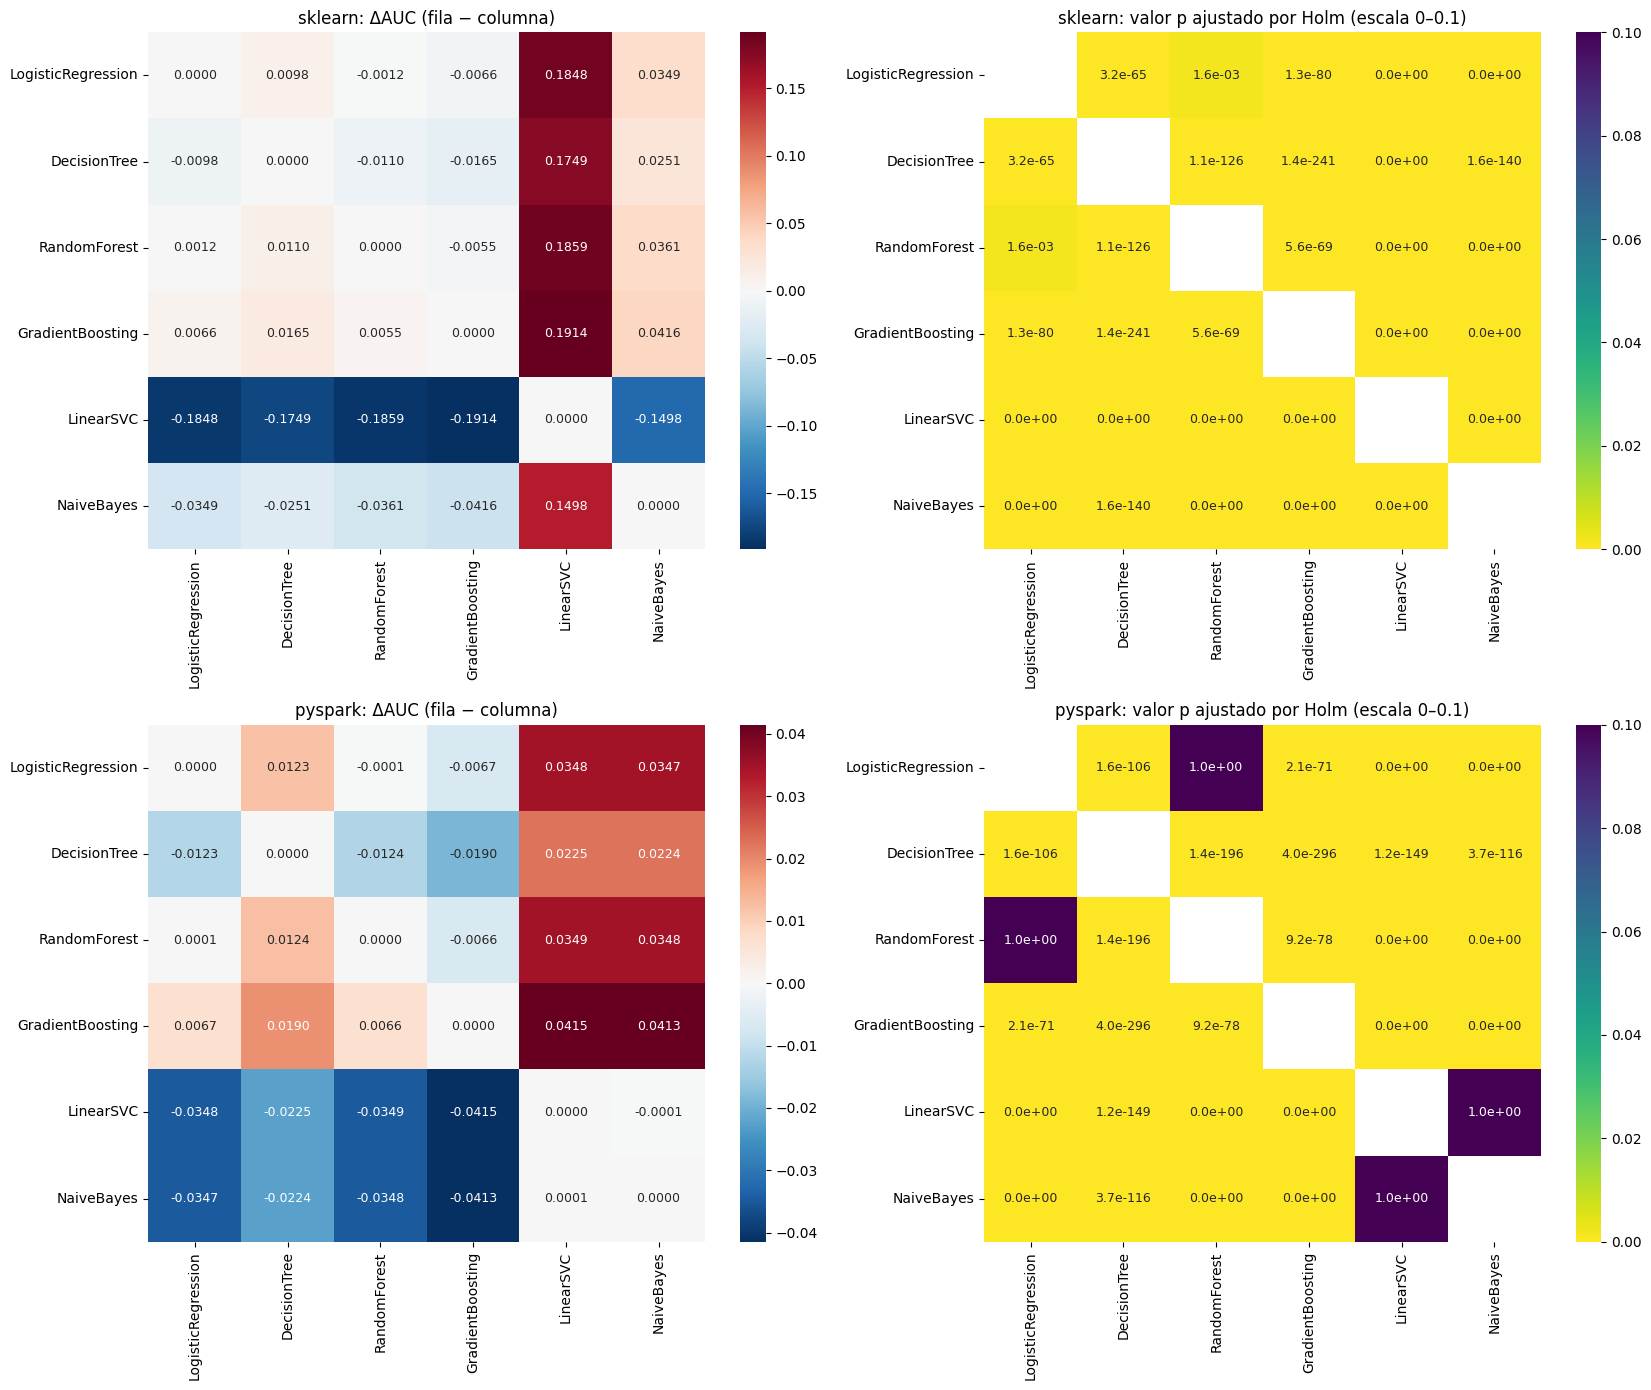

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(17, 14))  # Mapas de calor: ΔAUC y p ajustado por entorno
for fila, entorno in enumerate(["sklearn", "pyspark"]):  # Una fila por entorno
    t = dentro[entorno]  # Resultados del entorno
    delta = pd.DataFrame(0.0, index=cfg.NOMBRES_MODELOS, columns=cfg.NOMBRES_MODELOS)  # Matriz de ΔAUC (fila − columna)
    pmat = pd.DataFrame(np.nan, index=cfg.NOMBRES_MODELOS, columns=cfg.NOMBRES_MODELOS)  # Matriz de p ajustados
    for _, r in t.iterrows():  # Llena ambas matrices de forma simétrica
        delta.loc[r.modelo_1, r.modelo_2], delta.loc[r.modelo_2, r.modelo_1] = r.delta_auc, -r.delta_auc  # ΔAUC antisimétrico
        pmat.loc[r.modelo_1, r.modelo_2] = pmat.loc[r.modelo_2, r.modelo_1] = r.p_holm  # p ajustado simétrico
    sns.heatmap(delta, annot=True, fmt=".4f", cmap="RdBu_r", center=0, ax=axes[fila, 0], annot_kws={"size": 9})  # Mapa de ΔAUC
    axes[fila, 0].set_title(f"{entorno}: ΔAUC (fila − columna)")  # Título
    sns.heatmap(pmat, annot=True, fmt=".1e", cmap="viridis_r", vmin=0, vmax=0.1, ax=axes[fila, 1], annot_kws={"size": 9})  # Mapa de p ajustados
    axes[fila, 1].set_title(f"{entorno}: valor p ajustado por Holm (escala 0–0.1)")  # Título
fig.tight_layout()  # Ajusta márgenes
guardar_figura(fig, "05_heatmaps_delong")  # Exporta la figura
plt.show()  # Muestra la figura

## 5.3 Pruebas complementarias: McNemar y bootstrap pareado

**Umbral de decisión.** Para cada modelo se usa el umbral que maximiza F1 **en el
conjunto de entrenamiento** (calculado en los notebooks 03 y 04, sin tocar test). Con una
clase positiva del ~20 %, el umbral de 0.5 dejaría a varios modelos casi sin predecir
defaults, lo que haría la comparación de errores poco informativa.

In [9]:
met_sk = leer_json(cfg.RUTA_METRICAS_SK)["modelos"]  # Métricas y umbrales de scikit-learn
met_sp = leer_json(cfg.RUTA_METRICAS_SP)["modelos"]  # Métricas y umbrales de PySpark
umbral = {**{f"sklearn|{k}": v["umbral"] for k, v in met_sk.items()}, **{f"pyspark|{k}": v["umbral"] for k, v in met_sp.items()}}  # Umbral por modelo
top = {}  # Los dos modelos con mayor AUC de cada entorno
for entorno in ["sklearn", "pyspark"]:  # Recorre los entornos
    aucs = tabla_auc["AUC"][entorno].sort_values(ascending=False)  # AUC ordenados de mayor a menor
    top[entorno] = aucs.index[:2].tolist()  # Los dos primeros
print("Pares con mayor AUC:", top)  # Muestra los pares elegidos
pd.Series(umbral, name="umbral_train").to_frame()  # Muestra los umbrales

Pares con mayor AUC: {'sklearn': ['GradientBoosting', 'RandomForest'], 'pyspark': ['GradientBoosting', 'RandomForest']}


,umbral_train
sklearn|LogisticRegression,0.214241
sklearn|DecisionTree,0.21421
sklearn|RandomForest,0.245074
sklearn|GradientBoosting,0.214676
sklearn|LinearSVC,-1
sklearn|NaiveBayes,0.0738859
pyspark|LogisticRegression,0.212474
pyspark|DecisionTree,0.215241
pyspark|RandomForest,0.240502
pyspark|GradientBoosting,0.214045


In [10]:
comparaciones = [(f"{m}: sklearn vs PySpark", f"sklearn|{m}", f"pyspark|{m}", "entre_entornos") for m in cfg.NOMBRES_MODELOS]  # 6 comparaciones entre entornos
comparaciones += [(f"{e}: {top[e][0]} vs {top[e][1]}", f"{e}|{top[e][0]}", f"{e}|{top[e][1]}", "top2_por_entorno") for e in ["sklearn", "pyspark"]]  # 2 pares de mejores modelos
filas = []  # Resultados combinados
for nombre, c1, c2, familia in comparaciones:  # Recorre las 8 comparaciones
    s1, s2 = datos[c1].to_numpy(), datos[c2].to_numpy()  # Puntuaciones de ambos modelos
    dl = delong.prueba_delong(y, s1, s2)  # DeLong
    mc = prueba_mcnemar(y, (s1 >= umbral[c1]).astype(int), (s2 >= umbral[c2]).astype(int))  # McNemar con umbrales de train
    t0 = time.time()  # Inicio del bootstrap
    bs = bootstrap_pareado(y, s1, s2, umbral[c1], umbral[c2], B=cfg.B_BOOTSTRAP, semilla=cfg.SEMILLA)  # Bootstrap pareado
    filas.append({"comparacion": nombre, "familia": familia,  # Identificación
                  "delong_delta_auc": dl["delta_auc"], "delong_ic_inf": dl["delta_ic_inf"], "delong_ic_sup": dl["delta_ic_sup"], "delong_z": dl["z"], "delong_p": dl["p_valor"],  # DeLong
                  "mcnemar_b": mc["b"], "mcnemar_c": mc["c"], "mcnemar_chi2": mc["estadistico"], "mcnemar_p": mc["p_valor"], "mcnemar_exacta": mc["exacta"],  # McNemar
                  **{f"boot_{k}": v for k, v in bs.items()}})  # Bootstrap
    print(f"{nombre}: bootstrap en {time.time() - t0:.1f} s", flush=True)  # Progreso
comp = pd.DataFrame(filas).set_index("comparacion")  # Tabla combinada
for familia in comp["familia"].unique():  # Holm dentro de cada familia
    f = comp["familia"] == familia  # Filas de la familia
    for p in ["delong_p", "mcnemar_p", "boot_delta_auc_p", "boot_delta_auc_pr_p", "boot_delta_f1_p"]:  # Cada prueba/métrica
        comp.loc[f, p + "_holm"] = holm(comp.loc[f, p], cfg.ALFA)[0]  # Valor p ajustado por Holm

LogisticRegression: sklearn vs PySpark: bootstrap en 26.7 s


DecisionTree: sklearn vs PySpark: bootstrap en 8.8 s


RandomForest: sklearn vs PySpark: bootstrap en 27.2 s


GradientBoosting: sklearn vs PySpark: bootstrap en 28.7 s


LinearSVC: sklearn vs PySpark: bootstrap en 29.2 s


NaiveBayes: sklearn vs PySpark: bootstrap en 28.9 s


sklearn: GradientBoosting vs RandomForest: bootstrap en 29.1 s


pyspark: GradientBoosting vs RandomForest: bootstrap en 29.2 s


### Resultados detallados

In [11]:
comp[["familia", "delong_delta_auc", "delong_ic_inf", "delong_ic_sup", "delong_z", "delong_p", "delong_p_holm"]]  # DeLong

,familia,delong_delta_auc,delong_ic_inf,delong_ic_sup,delong_z,delong_p,delong_p_holm
comparacion,,,,,,,
LogisticRegression: sklearn vs PySpark,entre_entornos,-1.11431e-05,-3.39499e-05,1.16637e-05,-0.957612,0.338259,0.676517
DecisionTree: sklearn vs PySpark,entre_entornos,0.00245089,0.00149492,0.00340686,5.0249,5.03692e-07,1.51108e-06
RandomForest: sklearn vs PySpark,entre_entornos,0.00105734,0.000731372,0.00138331,6.3575,2.05068e-10,8.20271e-10
GradientBoosting: sklearn vs PySpark,entre_entornos,-4.54533e-05,-0.00043838,0.000347473,-0.226727,0.820636,0.820636
LinearSVC: sklearn vs PySpark,entre_entornos,-0.149986,-0.153423,-0.146549,-85.5268,0,0
NaiveBayes: sklearn vs PySpark,entre_entornos,-0.00030454,-0.000359848,-0.000249232,-10.7921,3.75161e-27,1.87581e-26
sklearn: GradientBoosting vs RandomForest,top2_por_entorno,0.00545408,0.00484726,0.0060609,17.6161,1.85286e-69,1.85286e-69
pyspark: GradientBoosting vs RandomForest,top2_por_entorno,0.00655687,0.00587114,0.00724261,18.7409,2.29811e-78,4.59623e-78


In [12]:
comp[["mcnemar_b", "mcnemar_c", "mcnemar_chi2", "mcnemar_exacta", "mcnemar_p", "mcnemar_p_holm"]]  # McNemar

,mcnemar_b,mcnemar_c,mcnemar_chi2,mcnemar_exacta,mcnemar_p,mcnemar_p_holm
comparacion,,,,,,
LogisticRegression: sklearn vs PySpark,1135,319,456.826,False,2.35838e-101,9.43353e-101
DecisionTree: sklearn vs PySpark,18549,11787,1506.83,False,0,0
RandomForest: sklearn vs PySpark,5413,3812,277.507,False,2.62374e-62,7.87123e-62
GradientBoosting: sklearn vs PySpark,5555,6250,40.7993,False,1.68692e-10,3.37383e-10
LinearSVC: sklearn vs PySpark,16471,119601,78161.5,False,0,0
NaiveBayes: sklearn vs PySpark,742,797,1.89474,False,0.168669,0.168669
sklearn: GradientBoosting vs RandomForest,7457,18142,4459.07,False,0,0
pyspark: GradientBoosting vs RandomForest,8838,17227,2699.35,False,0,0


In [13]:
comp[[c for c in comp.columns if c.startswith("boot_")]].T  # Bootstrap pareado (ΔAUC, ΔAUC-PR, ΔF1)

comparacion,LogisticRegression: sklearn vs PySpark,DecisionTree: sklearn vs PySpark,RandomForest: sklearn vs PySpark,GradientBoosting: sklearn vs PySpark,LinearSVC: sklearn vs PySpark,NaiveBayes: sklearn vs PySpark,sklearn: GradientBoosting vs RandomForest,pyspark: GradientBoosting vs RandomForest
boot_delta_auc,-1.07829e-05,0.00246193,0.00105299,-4.08004e-05,-0.149985,-0.000304166,0.00545803,0.00655182
boot_delta_auc_ic_inf,-3.35031e-05,0.00147575,0.000739802,-0.000424747,-0.153389,-0.000359262,0.0048622,0.00586054
boot_delta_auc_ic_sup,1.16176e-05,0.00339225,0.00138226,0.000331819,-0.146624,-0.000248693,0.00609944,0.00725128
boot_delta_auc_difiere,False,True,True,False,True,True,True,True
boot_delta_auc_p,0.361,0.0005,0.0005,0.823,0.0005,0.0005,0.0005,0.0005
boot_delta_auc_pr,-0.000145269,0.00445726,0.00078234,0.000226047,-0.103054,-0.000720251,0.00810916,0.00866545
boot_delta_auc_pr_ic_inf,-0.000202581,0.00248761,7.54609e-05,-0.000679186,-0.106309,-0.000853549,0.00681018,0.00725075
boot_delta_auc_pr_ic_sup,-8.73936e-05,0.00629229,0.00154232,0.00115919,-0.0998786,-0.000594301,0.00939243,0.0100543
boot_delta_auc_pr_difiere,True,True,True,False,True,True,True,True
boot_delta_auc_pr_p,0.0005,0.0005,0.037,0.638,0.0005,0.0005,0.0005,0.0005


### 5.4 Tabla resumen de las tres pruebas

In [14]:
def veredicto(p, alfa=cfg.ALFA):  # Traduce un valor p ajustado a texto
    return "difiere" if p < alfa else "no difiere"  # Decisión al 5 %

resumen = pd.DataFrame({  # Una fila por comparación
    "ΔAUC": comp["delong_delta_auc"],  # Diferencia de AUC
    "IC95 ΔAUC (DeLong)": [f"[{a:.4f}, {b:.4f}]" for a, b in zip(comp["delong_ic_inf"], comp["delong_ic_sup"])],  # IC de DeLong
    "DeLong (p Holm)": comp["delong_p_holm"],  # p ajustado de DeLong
    "DeLong": comp["delong_p_holm"].map(veredicto),  # Decisión de DeLong
    "Relevante |ΔAUC|≥0.005": comp["delong_delta_auc"].abs() >= cfg.MARGEN_RELEVANCIA_AUC,  # Relevancia práctica
    "McNemar (p Holm)": comp["mcnemar_p_holm"],  # p ajustado de McNemar
    "McNemar": comp["mcnemar_p_holm"].map(veredicto),  # Decisión de McNemar
    "Boot ΔAUC IC95": [f"[{a:.4f}, {b:.4f}]" for a, b in zip(comp["boot_delta_auc_ic_inf"], comp["boot_delta_auc_ic_sup"])],  # IC bootstrap de ΔAUC
    "Boot ΔAUC-PR IC95": [f"[{a:.4f}, {b:.4f}]" for a, b in zip(comp["boot_delta_auc_pr_ic_inf"], comp["boot_delta_auc_pr_ic_sup"])],  # IC bootstrap de ΔAUC-PR
    "Boot ΔF1 IC95": [f"[{a:.4f}, {b:.4f}]" for a, b in zip(comp["boot_delta_f1_ic_inf"], comp["boot_delta_f1_ic_sup"])],  # IC bootstrap de ΔF1
    "Boot ΔAUC": comp["boot_delta_auc_p_holm"].map(veredicto),  # Decisión bootstrap AUC
    "Boot ΔAUC-PR": comp["boot_delta_auc_pr_p_holm"].map(veredicto),  # Decisión bootstrap AUC-PR
    "Boot ΔF1": comp["boot_delta_f1_p_holm"].map(veredicto),  # Decisión bootstrap F1
})
resumen["DeLong = Boot (AUC)"] = resumen["DeLong"] == resumen["Boot ΔAUC"]  # ¿Coinciden DeLong y bootstrap para el AUC?
resumen  # Muestra la tabla resumen

,ΔAUC,IC95 ΔAUC (DeLong),DeLong (p Holm),DeLong,Relevante |ΔAUC|≥0.005,McNemar (p Holm),McNemar,Boot ΔAUC IC95,Boot ΔAUC-PR IC95,Boot ΔF1 IC95,Boot ΔAUC,Boot ΔAUC-PR,Boot ΔF1,DeLong = Boot (AUC)
comparacion,,,,,,,,,,,,,,
LogisticRegression: sklearn vs PySpark,-1.11431e-05,"[-0.0000, 0.0000]",0.676517,no difiere,False,9.43353e-101,difiere,"[-0.0000, 0.0000]","[-0.0002, -0.0001]","[-0.0002, 0.0006]",no difiere,difiere,no difiere,True
DecisionTree: sklearn vs PySpark,0.00245089,"[0.0015, 0.0034]",1.51108e-06,difiere,False,0,difiere,"[0.0015, 0.0034]","[0.0025, 0.0063]","[0.0014, 0.0050]",difiere,difiere,difiere,True
RandomForest: sklearn vs PySpark,0.00105734,"[0.0007, 0.0014]",8.20271e-10,difiere,False,7.87123e-62,difiere,"[0.0007, 0.0014]","[0.0001, 0.0015]","[-0.0007, 0.0016]",difiere,no difiere,no difiere,True
GradientBoosting: sklearn vs PySpark,-4.54533e-05,"[-0.0004, 0.0003]",0.820636,no difiere,False,3.37383e-10,difiere,"[-0.0004, 0.0003]","[-0.0007, 0.0012]","[-0.0006, 0.0016]",no difiere,no difiere,no difiere,True
LinearSVC: sklearn vs PySpark,-0.149986,"[-0.1534, -0.1465]",0,difiere,True,0,difiere,"[-0.1534, -0.1466]","[-0.1063, -0.0999]","[-0.0724, -0.0682]",difiere,difiere,difiere,True
NaiveBayes: sklearn vs PySpark,-0.00030454,"[-0.0004, -0.0002]",1.87581e-26,difiere,False,0.168669,no difiere,"[-0.0004, -0.0002]","[-0.0009, -0.0006]","[-0.0008, -0.0001]",difiere,difiere,difiere,True
sklearn: GradientBoosting vs RandomForest,0.00545408,"[0.0048, 0.0061]",1.85286e-69,difiere,True,0,difiere,"[0.0049, 0.0061]","[0.0068, 0.0094]","[0.0068, 0.0103]",difiere,difiere,difiere,True
pyspark: GradientBoosting vs RandomForest,0.00655687,"[0.0059, 0.0072]",4.59623e-78,difiere,True,0,difiere,"[0.0059, 0.0073]","[0.0073, 0.0101]","[0.0069, 0.0104]",difiere,difiere,difiere,True


In [15]:
comp.to_csv(cfg.DIR_SALIDAS / "comparaciones_complementarias.csv")  # Guarda la tabla combinada
fam1.to_csv(cfg.DIR_SALIDAS / "delong_entre_entornos.csv")  # Guarda la familia 1
for entorno, t in dentro.items():  # Guarda la familia 2 de cada entorno
    t.to_csv(cfg.DIR_SALIDAS / f"delong_dentro_{entorno}.csv", index=False)  # Un CSV por entorno
tabla_auc.to_csv(cfg.DIR_SALIDAS / "auc_ic95.csv")  # Guarda los AUC con IC
print("Resultados guardados en", cfg.DIR_SALIDAS)  # Confirma el guardado

Resultados guardados en C:\Users\user-pc\Documents\DanielSerranoRomero\Maestría\MachineLearning\Projects\proyecto_integrador_ml\outputs


## 5.2 Interpretación y limitaciones

**Validación.** La versión rápida de DeLong coincide con la directa hasta el error de redondeo
(|ΔAUC| ≈ 1e-16, |Δcov| ≈ 1e-19) tanto en datos sintéticos con empates como en 3.000
observaciones reales; además, sus AUC coinciden con `roc_auc_score`.

**Familia 1 – mismo modelo en ambos entornos (Holm, α = 0,05).**

| Modelo | ΔAUC (sklearn − PySpark) | p Holm | ¿Significativa? | ¿Relevante (≥ 0,005)? |
|---|---|---|---|---|
| Regresión logística | −0,00001 | 0,68 | No | No |
| Árbol de decisión | +0,0025 | < 0,001 | Sí | No |
| Bosque aleatorio | +0,0011 | < 0,001 | Sí | No |
| *Gradient boosting* | −0,00005 | 0,82 | No | No |
| LinearSVC | −0,150 | < 0,001 | Sí | **Sí** |
| Naive Bayes | −0,0003 | < 0,001 | Sí | No |

Regresión logística y *gradient boosting* son **estadísticamente indistinguibles** entre
entornos. En árbol, bosque y Naive Bayes las diferencias son significativas pero diminutas
(≤ 0,0025, la mitad del margen de relevancia): con 269 mil observaciones y curvas ROC muy
correlacionadas, el error estándar de ΔAUC es del orden de 0,0001–0,0005, así que la prueba
detecta diferencias sin importancia práctica. Solo LinearSVC difiere de forma relevante.

**Familia 2 – pares dentro de cada entorno.** En scikit-learn los 15 pares difieren tras
Holm; en PySpark 13 de 15 (no difieren regresión logística vs bosque, p = 1, ni LinearSVC vs
Naive Bayes, p = 1). Con el margen de relevancia, el orden práctico es el mismo en ambos
entornos: **boosting** (mejor que todos por ≥ 0,0055) > **bosque ≈ logística** (diferencia
≤ 0,0012, irrelevante) > **árbol** > **Naive Bayes** (≈ LinearSVC en PySpark); LinearSVC de
scikit-learn es el último.

**Pruebas complementarias (8 comparaciones).**
* **Bootstrap vs DeLong (AUC):** coinciden en las 8 comparaciones, y los intervalos son
  prácticamente idénticos (p. ej., bosque: DeLong [0,0007; 0,0014], bootstrap [0,0007;
  0,0014]). Es lo esperable: con n grande la aproximación normal de DeLong es excelente.
* **AUC-PR y F1 (bootstrap):** cuentan una historia algo distinta. En la regresión logística el
  AUC-PR difiere (−0,00015, irrelevante) aunque el AUC no; en el bosque el AUC-PR deja de ser
  significativo tras Holm (p = 0,074) y el F1 no difiere. Entre los mejores modelos de cada
  entorno, el boosting supera al bosque en las tres métricas (ΔAUC-PR ≈ +0,008; ΔF1 ≈ +0,009).
* **McNemar:** declara diferencias en casi todas las comparaciones, incluso donde DeLong no las
  ve (regresión logística: b = 1.135, c = 319; boosting: 5.555 vs 6.250). La razón es que compara
  **decisiones** con umbrales elegidos por separado en cada entorno (0,2142 vs 0,2125 en la
  logística): un corrimiento mínimo del umbral cambia la decisión de miles de préstamos cercanos
  a la frontera sin alterar la ordenación. En Naive Bayes ocurre lo contrario: DeLong detecta
  una diferencia ínfima de ordenación, pero las decisiones coinciden (p = 0,17).
* **Boosting vs bosque (McNemar):** hay **más** casos en que acierta el bosque y falla el
  boosting (18.142) que al revés (7.457), a pesar de que el boosting tiene mejor AUC, AUC-PR y
  F1. El umbral del bosque (0,245) es más alto, así que predice menos defaults: comete menos
  falsos positivos (clase mayoritaria) y más falsos negativos. McNemar cuenta todos los errores
  por igual, y con una clase minoritaria del 20 % eso favorece al modelo más conservador aunque
  detecte menos defaults. Es exactamente la limitación que pide discutir la sección 5.3.

**Limitaciones de la prueba de DeLong en este diseño.**
1. Solo captura la variabilidad del **muestreo del conjunto de prueba**. No incluye la
   variabilidad del entrenamiento (semillas, pliegues de la validación cruzada, aleatoriedad del
   bosque): otra semilla podría mover los AUC más que las diferencias entre entornos detectadas.
2. Supone observaciones independientes; los préstamos de un mismo periodo o región comparten
   condiciones económicas, así que el error estándar real puede ser mayor.
3. El AUC resume todos los umbrales; en la operación solo importa uno. Dos modelos con igual AUC
   pueden tomar decisiones distintas (regresión logística y boosting entre entornos, según
   McNemar) y un modelo con mejor AUC puede cometer más errores totales en su umbral
   (boosting vs bosque).
4. Con n ≈ 269 mil, la significancia estadística es casi automática: por eso se fijó de antemano
   el margen de relevancia |ΔAUC| ≥ 0,005 (1 punto de Gini).